# Set Up

In [1]:
from pcj.utils import dados
from pcj.modelos_ML import selecao_k, k_means, random_forest, knn_regressor
from pcj.visualizacoes import curvas_selecao_k

In [2]:
df, metadados, variaveis = dados(r"data\processed\dados_med_tratados.xlsx")

# K-Means
## Escolha de k
Base tratada (`dados_med_tratados.xlsx`: médias mensais, outliers tratados). k de 2 a 10, 30 seeds cada, no espaço da detecção (meses completos, padronizados e reduzidos por PCA). A silhueta decide; o cotovelo e o Calinski-Harabasz confirmam.

In [3]:
# rodadas_k: uma linha por (k, seed); resumo_k: uma linha por k; k_km: o k da maior silhueta média
rodadas_k, resumo_k, k_km = selecao_k(df, variaveis, verbose=True)
resumo_k

K-Means em 118 meses completos (73 com NaN, não avaliados); 12 componentes principais
k de 2 a 10 x 30 seeds = 270 rodadas
Silhueta (maior média): k = 2
Cotovelo da inércia (kneed): k = 4
Calinski-Harabasz (maior média): k = 2
k escolhido (a silhueta decide): 2


,k,inercia_media,inercia_dp,silhueta_media,silhueta_dp,calinski_harabasz_media,calinski_harabasz_dp,indicado_silhueta,indicado_cotovelo,indicado_calinski_harabasz
0,2,1382.254520,1.459813,0.203861,0.000553,36.287913,0.160810,True,False,True
1,3,1214.060933,45.986711,0.177622,0.017505,28.558782,3.098376,False,False,False
2,4,1113.929880,12.743735,0.150997,0.031599,23.912080,0.704565,False,True,False
3,5,1043.598763,15.091362,0.132323,0.024363,20.882253,0.702407,False,False,False
4,6,981.105958,17.431081,0.124848,0.017360,19.043722,0.731485,False,False,False
5,7,925.603521,17.543870,0.123762,0.019883,17.781956,0.679295,False,False,False
6,8,875.157000,15.811352,0.126399,0.015158,16.879843,0.583304,False,False,False
7,9,830.891379,15.655073,0.123545,0.014915,16.142094,0.561454,False,False,False
8,10,793.861250,18.681199,0.119388,0.017249,15.444982,0.642718,False,False,False


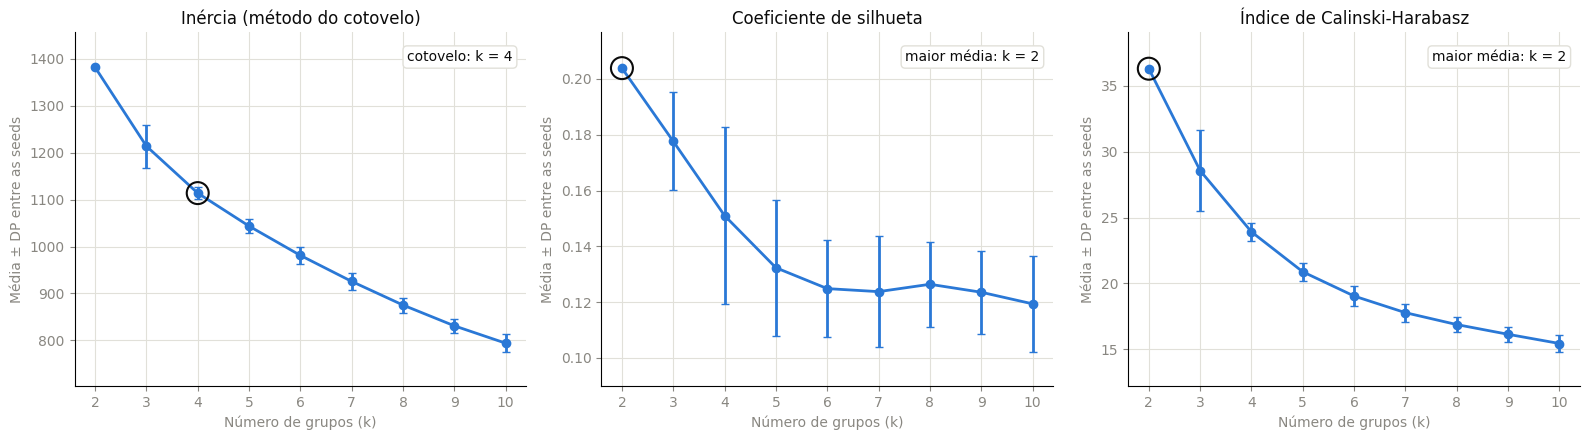

In [4]:
curvas_selecao_k(resumo_k, plot=True, salvar=False)

## Grupos
K-Means com o k escolhido (o melhor de 10 inícios). `tabela_km` tem o grupo de cada mês (as figuras ficam em `aplicacoes/visualizacoes`); `perfil_km` tem a média de cada variável por grupo, na unidade original.

In [5]:
tabela_km, perfil_km = k_means(df, variaveis, n_clusters=k_km, verbose=True)
perfil_km

K-Means com k = 2 em 118 meses completos (73 com NaN, não agrupados); 12 componentes principais
Meses por grupo: [62, 56]


,grupo,meses,COR,TURB.,pH,ALC.,AC.,O.C.,O.D.,Cl,DUR.,Fe,Mn,Cond.,Cianobacteria,C.F.,Clorofila,F
0,0,62,170.903226,99.290323,7.277419,44.693548,10.080645,8.103226,3.383871,30.903226,45.645161,3.235000,0.187903,216.564516,6756.500000,31943.548387,20.133065,0.222226
1,1,56,57.928571,19.160714,7.396429,74.142857,11.107143,8.416071,2.698214,48.589286,60.553571,1.028571,0.157500,416.928571,14541.482143,13180.535714,46.591964,0.333750


# Random Forest
Regressão do pH pelas outras variáveis, com validação cruzada em 5 blocos de meses seguidos.

In [6]:
random_forest(df, variaveis)

RMSE: 0.13022080335767627
MAE: 0.10405084745762709
r²: 0.26010391075457795
R² de cada bloco: [0.162, -0.268, 0.375, -0.103, 0.145]
R² dos blocos: média 0.062 ± DP 0.250


# KNN Regressor
Cada variável prevista pelas outras, com validação cruzada em 5 blocos de meses seguidos (GridSearch dentro de cada bloco).

In [7]:
knn_regressor(df, variaveis)

,variavel,rmse,mae,r2,r2_blocos,melhores_parametros,n_blocos_parametros
0,COR,0.093951,0.045102,0.496810,"[0.387, 0.471, 0.797, 0.638, 0.813]","{'metric': 'manhattan', 'n_neighbors': 3, 'wei...",2
1,TURB.,0.184029,0.123076,0.468770,"[0.614, 0.375, 0.433, 0.342, 0.414]","{'metric': 'manhattan', 'n_neighbors': 15, 'we...",1
2,pH,0.201620,0.159805,0.130892,"[0.201, -0.337, 0.195, -0.306, -0.099]","{'metric': 'euclidean', 'n_neighbors': 13, 'we...",2
3,ALC.,0.127845,0.094001,0.553414,"[0.688, 0.029, 0.498, 0.454, 0.477]","{'metric': 'manhattan', 'n_neighbors': 5, 'wei...",2
4,AC.,0.196787,0.134186,-0.135784,"[-0.438, -0.094, -0.268, -0.47, -0.521]","{'metric': 'euclidean', 'n_neighbors': 13, 'we...",1
5,O.C.,0.138703,0.101267,-0.113796,"[-0.762, -0.597, -0.55, 0.023, -0.466]","{'metric': 'manhattan', 'n_neighbors': 15, 'we...",1
6,O.D.,0.171232,0.135977,0.196735,"[0.297, 0.424, 0.297, 0.1, -1.824]","{'metric': 'manhattan', 'n_neighbors': 5, 'wei...",2
7,Cl,0.115457,0.084249,0.474154,"[-0.229, 0.458, 0.073, 0.659, 0.62]","{'metric': 'euclidean', 'n_neighbors': 9, 'wei...",1
8,DUR.,0.157163,0.117201,0.201696,"[-0.573, -0.31, 0.42, -0.241, -1.019]","{'metric': 'manhattan', 'n_neighbors': 7, 'wei...",2
9,Fe,0.156080,0.094390,0.421603,"[0.32, -0.176, 0.425, 0.443, 0.683]","{'metric': 'manhattan', 'n_neighbors': 11, 'we...",2
